# Practical 6: Logistic Regression, Confusion Matrix, Precision, Recall and F1-score

**Subject:** Machine Learning  |  **Type:** Supervised learning, binary classification

## Aim
Illustrate the performance of a **binary classification model using logistic regression** on a suitable open-access dataset through a **confusion matrix, precision, recall and F1-score**.

## Dataset
**Breast Cancer Wisconsin (Diagnostic)** (scikit-learn): 569 patients, 30 numeric features, target = **malignant** or **benign**.

> **Important choice:** in scikit-learn's version 0 = malignant and 1 = benign. For medical screening the natural "positive" class is **malignant** (the disease we want to catch), so we flip the labels: **1 = malignant (positive), 0 = benign (negative)**. This makes precision and recall mean what a doctor would expect: *recall* = how many real cancers we catch.

## Steps
1. Load data, check class balance
2. Split with stratification, scale
3. Train logistic regression
4. Confusion matrix (counts and normalised)
5. Accuracy, precision, recall, F1, specificity (and by hand)
6. ROC curve, AUC and precision-recall curve
7. Effect of the decision threshold
8. Sigmoid curve and coefficients

## Step 0: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report, roc_curve, roc_auc_score,
                             precision_recall_curve)

sns.set_theme(style="whitegrid")

## Step 1: Load data and check the class balance

Shape: (569, 30)
Benign   : 357 | Malignant: 212


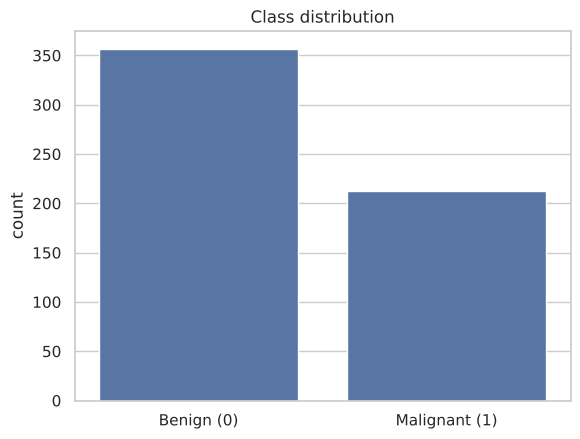

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = 1 - data.target          # flip: 1 = malignant (positive), 0 = benign (negative)
class_names = ["Benign (0)", "Malignant (1)"]

print("Shape:", X.shape)
print("Benign   :", (y == 0).sum(), "| Malignant:", (y == 1).sum())
sns.countplot(x=y); plt.xticks([0, 1], class_names); plt.title("Class distribution"); plt.show()

**How to read this:** the bars show how many patients are in each class. About 63% are benign and 37% malignant: mildly imbalanced, so accuracy alone can be slightly misleading and we also use precision, recall and F1.

## Step 2: Split (stratified) and scale

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)
print("Malignant share  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (455, 30) | Test: (114, 30)
Malignant share  train: 0.374 | test: 0.368


## Step 3: Train logistic regression

Logistic regression models the **probability** of the positive class using the **sigmoid** function:

$$P(y=1\mid x) = \sigma(z) = \frac{1}{1+e^{-z}}, \qquad z = b_0 + b_1x_1 + \dots + b_nx_n$$

A sample is classified as positive if $P \ge 0.5$ (the default threshold).

In [4]:
clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train_s, y_train)

y_pred = clf.predict(X_test_s)
y_prob = clf.predict_proba(X_test_s)[:, 1]      # probability of malignant

print("First 8 predicted probabilities:", y_prob[:8].round(3))
print("First 8 predicted classes      :", y_pred[:8])
print("First 8 actual classes         :", y_test[:8])

First 8 predicted probabilities: [0.    1.    0.043 0.576 0.509 0.001 0.762 0.001]
First 8 predicted classes      : [0 1 0 1 1 0 1 0]
First 8 actual classes         : [0 1 0 1 0 0 1 0]


## Step 4: Confusion matrix

[[71  1]
 [ 3 39]]
TN=71  FP=1  FN=3  TP=39


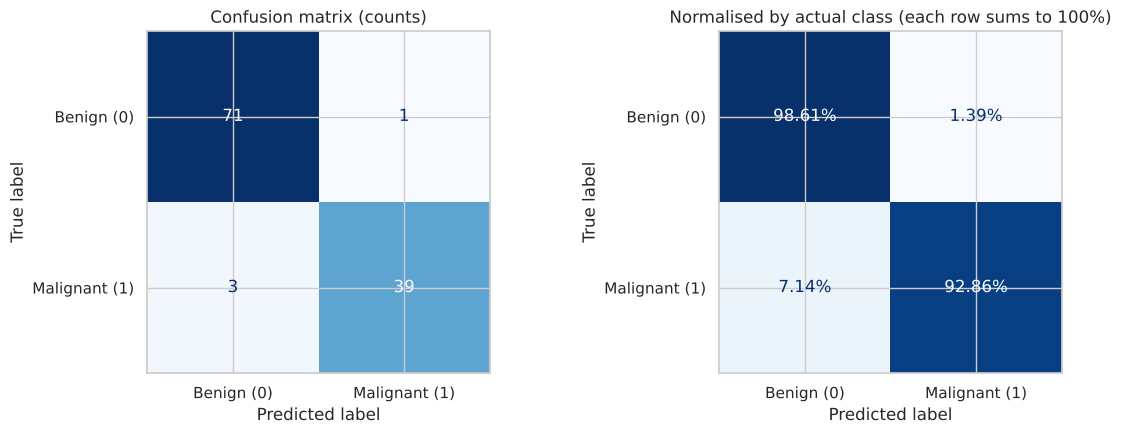

In [5]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(cm)
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, normalize="true"), display_labels=class_names).plot(
    ax=ax[1], cmap="Blues", colorbar=False, values_format=".2%")
ax[1].set_title("Normalised by actual class (each row sums to 100%)")
plt.tight_layout(); plt.show()

**Layout of the confusion matrix** (rows = actual, columns = predicted; positive = malignant)

| | Predicted benign (0) | Predicted malignant (1) |
|---|---|---|
| **Actual benign (0)** | **TN**: correctly cleared | **FP**: false alarm (Type I error) |
| **Actual malignant (1)** | **FN**: missed cancer (Type II error) | **TP**: correctly detected |

**How to read the heatmap:** the diagonal (top-left, bottom-right) holds correct predictions; the off-diagonal cells are mistakes. Dark diagonal and light off-diagonal means a good model. The normalised plot on the right shows percentages per actual class: the bottom-right value is the **recall** (share of real cancers detected) and the top-left is the **specificity**.

**Most dangerous cell:** **FN**, a malignant tumour predicted as benign, because the patient would go untreated.

## Step 5: Metrics

$$Accuracy=\frac{TP+TN}{TP+TN+FP+FN}\quad Precision=\frac{TP}{TP+FP}\quad Recall=\frac{TP}{TP+FN}\quad F1=\frac{2\cdot P\cdot R}{P+R}\quad Specificity=\frac{TN}{TN+FP}$$

In [6]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
spec = tn / (tn + fp)

print(f"Accuracy   : {acc:.4f}")
print(f"Precision  : {prec:.4f}")
print(f"Recall     : {rec:.4f}")
print(f"F1-score   : {f1:.4f}")
print(f"Specificity: {spec:.4f}")

# Same numbers by hand from the confusion matrix
print("\nBy hand ->",
      "Accuracy=%.4f" % ((tp + tn) / (tp + tn + fp + fn)),
      "| Precision=%.4f" % (tp / (tp + fp)),
      "| Recall=%.4f" % (tp / (tp + fn)),
      "| F1=%.4f" % (2 * (tp / (tp + fp)) * (tp / (tp + fn)) / ((tp / (tp + fp)) + (tp / (tp + fn)))))
print()
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))

Accuracy   : 0.9649
Precision  : 0.9750
Recall     : 0.9286
F1-score   : 0.9512
Specificity: 0.9861

By hand -> Accuracy=0.9649 | Precision=0.9750 | Recall=0.9286 | F1=0.9512

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



**Interpreting the numbers (in plain words)**
- **Precision:** out of all patients the model called malignant, this share really were malignant.
- **Recall:** out of all patients who really had a malignant tumour, this share were found.
- **F1:** the balance (harmonic mean) of precision and recall.
- In the classification report, `support` is the number of true samples of each class in the test set; `macro avg` is the simple average of the two classes and `weighted avg` weights by support.

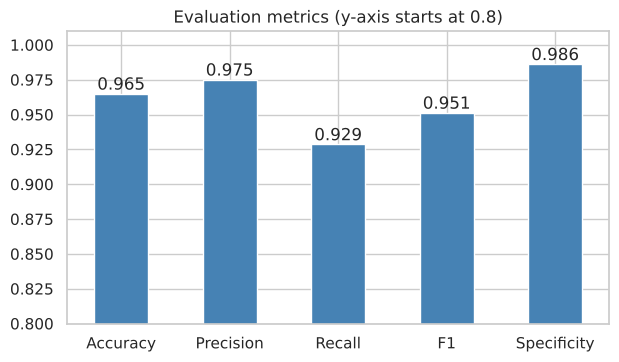

5-fold CV F1 scores: [0.977 0.976 0.963 0.964 0.988] | mean = 0.974


In [7]:
vals = pd.Series({"Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1, "Specificity": spec})
plt.figure(figsize=(7, 3.8))
vals.plot(kind="bar", color="steelblue", rot=0); plt.ylim(0.8, 1.01)
for i, v in enumerate(vals): plt.text(i, v + 0.003, f"{v:.3f}", ha="center")
plt.title("Evaluation metrics (y-axis starts at 0.8)"); plt.show()

cv = cross_val_score(LogisticRegression(max_iter=1000), StandardScaler().fit_transform(X), y, cv=5, scoring="f1")
print("5-fold CV F1 scores:", cv.round(3), "| mean = %.3f" % cv.mean())

## Step 6: ROC curve, AUC and precision-recall curve

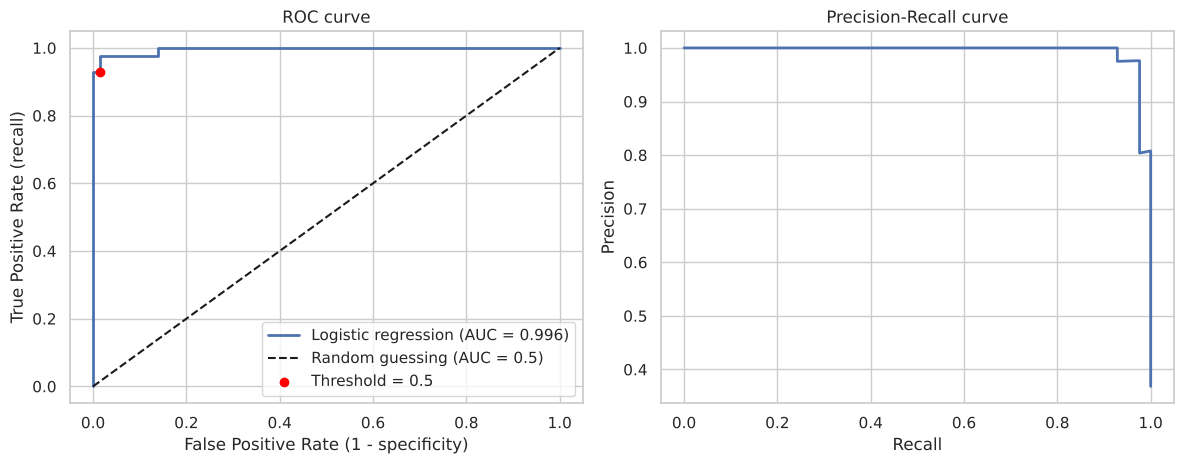

In [8]:
fpr, tpr, thr = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
p_arr, r_arr, pr_thr = precision_recall_curve(y_test, y_prob)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ax[0].plot(fpr, tpr, lw=2, label=f"Logistic regression (AUC = {auc:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="Random guessing (AUC = 0.5)")
ax[0].scatter([fp / (fp + tn)], [tp / (tp + fn)], color="red", zorder=5, label="Threshold = 0.5")
ax[0].set_xlabel("False Positive Rate (1 - specificity)"); ax[0].set_ylabel("True Positive Rate (recall)")
ax[0].set_title("ROC curve"); ax[0].legend(loc="lower right")

ax[1].plot(r_arr, p_arr, lw=2)
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-Recall curve")
plt.tight_layout(); plt.show()

**How to read the ROC curve:** it plots recall (TPR, y-axis) against the false alarm rate (FPR, x-axis) for **every possible threshold**. A curve that hugs the top-left corner is best; the dashed diagonal is random guessing. **AUC** (area under the curve) is 1.0 for a perfect model and 0.5 for random. The red dot marks where our default 0.5 threshold lies.

**How to read the Precision-Recall curve:** it shows the trade-off between precision and recall. A curve staying near the top-right is good. It is preferred over ROC when classes are imbalanced.

## Step 7: Effect of the decision threshold

Lowering the threshold makes the model call more patients malignant: **recall goes up, precision goes down**. Raising it does the opposite.

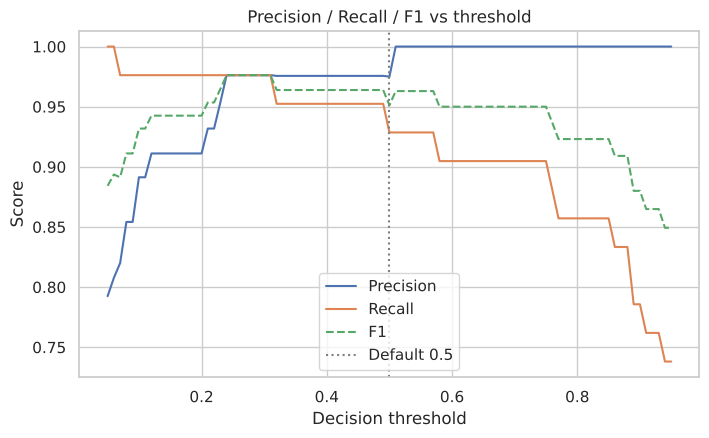

,Threshold,TP,FP,FN,TN,Precision,Recall
0,0.2,41,4,1,68,0.911,0.976
1,0.3,41,1,1,71,0.976,0.976
2,0.5,39,1,3,71,0.975,0.929
3,0.7,38,0,4,72,1.000,0.905
4,0.9,33,0,9,72,1.000,0.786


In [9]:
ths = np.linspace(0.05, 0.95, 91)
P, R, F = [], [], []
for t in ths:
    pr = (y_prob >= t).astype(int)
    P.append(precision_score(y_test, pr, zero_division=0))
    R.append(recall_score(y_test, pr))
    F.append(f1_score(y_test, pr, zero_division=0))

plt.figure(figsize=(8, 4.5))
plt.plot(ths, P, label="Precision"); plt.plot(ths, R, label="Recall"); plt.plot(ths, F, label="F1", ls="--")
plt.axvline(0.5, color="grey", ls=":", label="Default 0.5")
plt.xlabel("Decision threshold"); plt.ylabel("Score"); plt.legend(); plt.title("Precision / Recall / F1 vs threshold")
plt.show()

rows = []
for t in [0.2, 0.3, 0.5, 0.7, 0.9]:
    pr = (y_prob >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pr).ravel()
    rows.append({"Threshold": t, "TP": tp_, "FP": fp_, "FN": fn_, "TN": tn_,
                 "Precision": round(precision_score(y_test, pr, zero_division=0), 3),
                 "Recall": round(recall_score(y_test, pr), 3)})
pd.DataFrame(rows)

**How to read this:** as the threshold rises, **precision rises** (fewer false alarms) while **recall falls** (more missed cancers). For cancer screening we would choose a **lower threshold** to keep recall high (missing a cancer is worse than a false alarm that is checked with another test).

## Step 8: Sigmoid curve and the most influential features

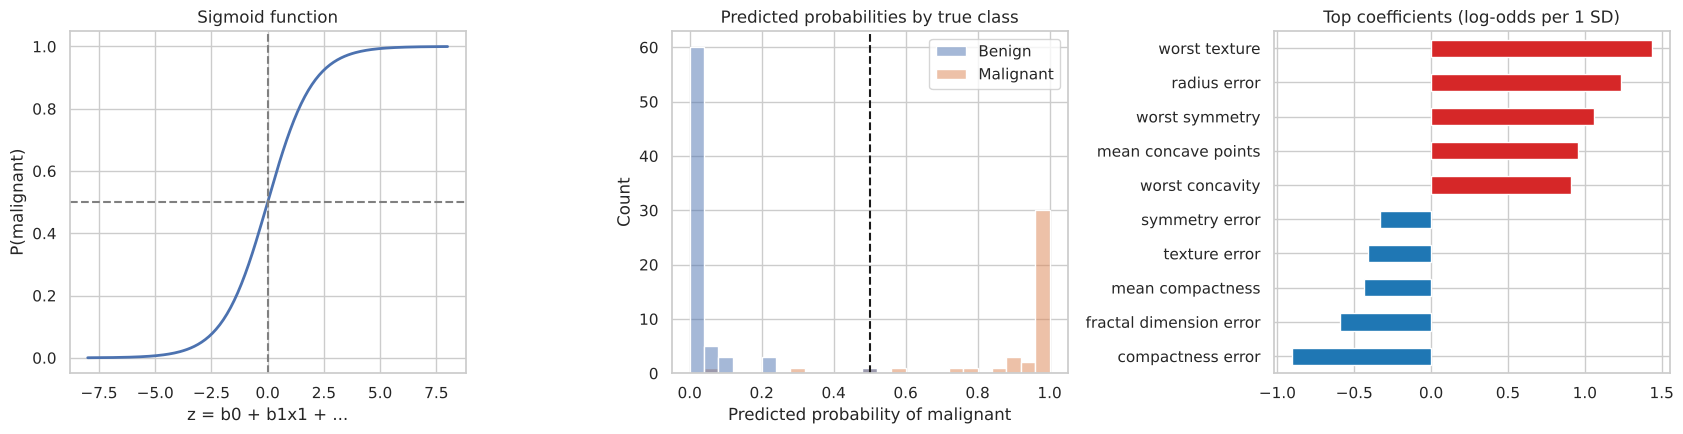

In [10]:
z = np.linspace(-8, 8, 200)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].plot(z, 1 / (1 + np.exp(-z)), lw=2)
ax[0].axhline(0.5, color="grey", ls="--"); ax[0].axvline(0, color="grey", ls="--")
ax[0].set_xlabel("z = b0 + b1x1 + ..."); ax[0].set_ylabel("P(malignant)"); ax[0].set_title("Sigmoid function")

sns.histplot(x=y_prob, hue=np.where(y_test == 1, "Malignant", "Benign"), bins=25, ax=ax[1], multiple="layer")
ax[1].axvline(0.5, color="k", ls="--"); ax[1].set_xlabel("Predicted probability of malignant")
ax[1].set_title("Predicted probabilities by true class")

coef = pd.Series(clf.coef_[0], index=data.feature_names).sort_values()
top = pd.concat([coef.head(5), coef.tail(5)])
top.plot(kind="barh", ax=ax[2], color=np.where(top > 0, "tab:red", "tab:blue"))
ax[2].set_title("Top coefficients (log-odds per 1 SD)")
plt.tight_layout(); plt.show()

**How to read these graphs**
1. **Sigmoid:** an S-shaped curve that turns any number $z$ into a probability between 0 and 1. It crosses 0.5 at $z=0$, which is the **decision boundary**.
2. **Probability histogram:** a good model pushes benign cases toward 0 and malignant cases toward 1, with little in the middle. The few bars near 0.5 are the uncertain cases and the likely errors.
3. **Coefficient chart:** red bars (positive) raise the log-odds of malignancy, blue bars (negative) lower it. Larger magnitude means a stronger influence (features are standardised so they are comparable).

## Result / Conclusion
- Logistic regression separated malignant from benign tumours with high accuracy, precision, recall and F1, and an AUC close to 1.
- The confusion matrix showed exactly which errors occurred (FP and FN), and the threshold analysis showed how to trade precision against recall depending on the cost of each error.
- For screening, recall (few missed cancers) is the most important metric.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is logistic regression? Is it regression or classification?**
Despite the name, it is a classification algorithm. It models the probability that an input belongs to class 1 using the sigmoid function and then applies a threshold (default 0.5).

**Q2. Why not use linear regression for classification?**
Linear regression outputs values outside 0 to 1, is sensitive to outliers, and its squared-error loss is not suited to categories. Logistic regression gives valid probabilities.

**Q3. What is the sigmoid function?**
$\sigma(z) = 1/(1+e^{-z})$. It squashes any real number into (0, 1), with $\sigma(0)=0.5$.

**Q4. What loss function does logistic regression use?**
Log loss (binary cross-entropy): $-[y\log p + (1-y)\log(1-p)]$, minimised with gradient descent or solvers such as lbfgs.

**Q5. What is the decision boundary?**
The surface where the predicted probability equals the threshold (0.5), i.e., where $z=0$. It is linear in logistic regression.

**Q6. What are odds and log-odds?**
Odds = $p/(1-p)$. Log-odds (logit) = $\log(p/(1-p)) = z$, a linear combination of the features. Each coefficient is the change in log-odds for a one-unit change in that feature; $e^{b}$ is the odds ratio.

**Q7. What is a confusion matrix?**
A table comparing actual and predicted classes: TP, TN, FP and FN counts.

**Q8. Define TP, TN, FP, FN.**
TP: predicted positive and actually positive. TN: predicted negative and actually negative. FP: predicted positive but actually negative (false alarm, Type I). FN: predicted negative but actually positive (missed case, Type II).

**Q9. Define accuracy, precision, recall and F1.**
Accuracy: share of all predictions that are correct. Precision: of predicted positives, how many are truly positive. Recall (sensitivity): of actual positives, how many were found. F1: harmonic mean of precision and recall.

**Q10. Why is accuracy not enough?**
With imbalanced classes a model that always predicts the majority class can have high accuracy but be useless. Precision, recall and F1 expose this.

**Q11. When do you prefer high precision and when high recall?**
High recall when missing a positive is costly (cancer screening, fraud). High precision when a false alarm is costly (spam filter blocking real mail, legal decisions).

**Q12. Why is F1 the harmonic mean and not the arithmetic mean?**
The harmonic mean is dominated by the lower value, so a model cannot get a high F1 by being excellent at one metric and terrible at the other.

**Q13. How does changing the threshold affect results?**
Lower threshold: more positives, recall up, precision down. Higher threshold: precision up, recall down.

**Q14. What is specificity?**
$TN/(TN+FP)$: the share of actual negatives correctly identified (true negative rate).

**Q15. What is the ROC curve and AUC?**
ROC plots TPR against FPR at all thresholds. AUC is the area under it: 1.0 is perfect, 0.5 is random. It equals the probability that a random positive is ranked above a random negative.

**Q16. ROC curve vs precision-recall curve: when to use which?**
Use PR curves for heavily imbalanced data because ROC can look optimistic when negatives dominate.

**Q17. What is the role of the regularisation parameter C?**
C is the inverse of regularisation strength. Small C means stronger regularisation (simpler model, less overfitting); large C means weaker regularisation. By default scikit-learn applies L2 regularisation.

**Q18. Can logistic regression do multiclass classification?**
Yes, using One-vs-Rest or the softmax (multinomial) approach.

**Q19. What are the assumptions of logistic regression?**
Binary (or categorical) target, independent observations, little multicollinearity, a linear relationship between features and the log-odds, and a reasonably large sample size.

**Q20. Why is `stratify=y` used?**
It keeps the same class proportions in the train and test sets, which matters for imbalanced data.

**Q21. Why did you scale the features?**
Logistic regression is solved by gradient-based optimisation and regularised; scaling speeds up convergence and makes coefficients comparable.

**Q22. What is Type I and Type II error?**
Type I = false positive (false alarm). Type II = false negative (missed detection).

**Q23. What are macro, micro and weighted averages?**
Macro: simple mean of per-class scores. Weighted: mean weighted by class support. Micro: computed globally from total TP, FP, FN (equals accuracy for single-label multiclass).

**Q24. Is logistic regression affected by outliers?**
Less than linear regression, but extreme values can still distort the fit; scaling and outlier handling help.

**Q25. Why did you treat malignant as the positive class?**
In screening, the event we want to detect is the disease. Treating it as positive means recall measures how many cancers we catch and FN is the dangerous error. (In scikit-learn's raw labels, 1 is benign, so the labels were flipped.)

## B. Questions about the graphs

**G1. How do you read the confusion matrix heatmap?**
Rows are actual classes and columns are predicted classes. The diagonal shows correct predictions; off-diagonal cells are mistakes. A dark diagonal and light off-diagonal means a good model.

**G2. Which cell is the most dangerous here?**
False Negative (bottom-left): a malignant tumour predicted as benign, so the patient is missed.

**G3. What does the normalised confusion matrix show?**
Percentages within each actual class. The bottom-right cell is recall and the top-left is specificity.

**G4. What does the ROC curve show?**
The trade-off between true positive rate (y) and false positive rate (x) at all thresholds. A curve near the top-left is best; the diagonal is random guessing.

**G5. What is AUC?**
Area Under the ROC Curve. 1.0 is perfect, 0.5 is random.

**G6. What does the sigmoid curve look like?**
An S-shape from 0 to 1 crossing 0.5 at z = 0. It turns any real number into a probability.

**G7. What does the precision/recall/F1 vs threshold plot show?**
As the threshold rises, precision generally increases and recall decreases; F1 peaks where the two are balanced. It helps choose a threshold for the application.

**G8. What does the probability histogram tell you?**
How confident the model is. Well-separated peaks near 0 and 1 mean confident, accurate predictions; bars near 0.5 are uncertain cases and the likely errors.

**G9. What does the coefficient bar chart show?**
The influence of each feature on the log-odds of malignancy: positive (red) increases risk, negative (blue) decreases it; larger bars matter more.

**G10. What does the class distribution bar chart tell you?**
Whether the classes are balanced. Here the data is mildly imbalanced (about 63% benign), so accuracy alone is not enough.

## C. Code questions

**C1. What is the difference between `predict` and `predict_proba`?**
`predict` returns class labels (using the 0.5 threshold). `predict_proba` returns the probability of each class.

**C2. Why `predict_proba(X)[:, 1]`?**
It selects the column with the probability of the positive class (class 1).

**C3. What does `confusion_matrix(y_true, y_pred).ravel()` return?**
The four counts in the order TN, FP, FN, TP (for labels 0 and 1).

**C4. Why `max_iter=1000`?**
The solver may need more iterations than the default (100) to converge.

**C5. Why is the scaler fitted only on training data?**
To avoid data leakage from the test set.

**C6. What does `zero_division=0` do?**
Returns 0 instead of a warning/error when a precision denominator is zero (no predicted positives).